In [1]:
import pandas as pd
from IPython.display import Image, display

from src.collection import Collection
from src.filter import ImageFilter, filter_images

&nbsp;

### **📂 Open collection**

In [2]:
collection = Collection()

Open Collection: E:\Resources\Eyeris\Test


&nbsp;

### **🖼️ Load all images**

In [3]:
images = collection.images_df()
images.head(5)

,id,origin,fullname,name,format,size,width,height,created,modified,rating,tags,hash,color_1,color_2,color_3,color_4,path,thumb_path
0,1,E:/Resources/Dataset/012.webp,012.webp,012,WEBP,8432346,3840,2160,1794203991530,1769960112000,4,lakeside,c34db2d144df3ff432eb28ce6efeaa0cc54c29aa2d7085...,7310413,3890462,9347248.0,1052676.0,E:\Resources\Eyeris\Test/images/c34db2d144df3f...,E:\Resources\Eyeris\Test/images/c34db2d144df3f...
1,2,E:/Resources/Dataset/voxel-houses-monochrome.webp,voxel-houses-monochrome.webp,voxel-houses-monochrome,WEBP,1796402,3840,2160,1794203991530,1789570720000,4,tank,9e032b32ece9a229983de22905af98e6de70b6e4597cd2...,4474458,1710888,2829372.0,6645627.0,E:\Resources\Eyeris\Test/images/9e032b32ece9a2...,E:\Resources\Eyeris\Test/images/9e032b32ece9a2...
2,3,E:/Resources/Dataset/house_garden.webp,house_garden.webp,house_garden,WEBP,483728,3840,2160,1794203991530,1789570720000,4,restaurant,e6cf0e8ff0304d0217fb1c591c98aaf75bb526532c135a...,13745760,11562290,5723436.0,2962979.0,E:\Resources\Eyeris\Test/images/e6cf0e8ff0304d...,E:\Resources\Eyeris\Test/images/e6cf0e8ff0304d...
3,4,E:/Resources/Dataset/macos-sonoma-wallpapers-5...,macos-sonoma-wallpapers-5120x2160-v0-q59obfq8h...,macos-sonoma-wallpapers-5120x2160-v0-q59obfq8h...,WEBP,5075530,5120,2160,1794203991530,1789570720000,5,cliff,bc1cc32311ef499f47ea59370365d1a3d9cc1546d2b261...,8029334,12697530,2499359.0,5065546.0,E:\Resources\Eyeris\Test/images/bc1cc32311ef49...,E:\Resources\Eyeris\Test/images/bc1cc32311ef49...
4,5,E:/Resources/Dataset/dream-river-4k.webp,dream-river-4k.webp,dream-river-4k,WEBP,7172958,3840,2160,1794203991530,1789570720000,5,lakeside,37033841e3ba46af1a3cf31f8e948d5850bccca469c1e3...,11037095,6238318,15121103.0,2887729.0,E:\Resources\Eyeris\Test/images/37033841e3ba46...,E:\Resources\Eyeris\Test/images/37033841e3ba46...


&nbsp;

### **🧰 Helper**

Show thumbnails of a filtered result.

In [4]:
def show(df: pd.DataFrame, limit: int = 5) -> None:
    print(f"{len(df)}/{len(images)} images matched")
    for row in df.head(limit).itertuples():
        display(Image(filename=row.thumb_path, width=256))  # ty: ignore[unresolved-attribute]

&nbsp;

### **🔎 Filter**

A filter is an `ImageFilter` (`TypedDict`).

Every key is optional, all conditions are combined with **AND**.

| Key | Type | Meaning |
| --- | --- | --- |
| `name` | `str` | name contains (case-insensitive) |
| `formats` | `list[str]` | format is one of, e.g. `["PNG", "JPG"]` |
| `min_size` / `max_size` | `int` | file size in bytes |
| `min_width` / `max_width` | `int` | width in pixels |
| `min_height` / `max_height` | `int` | height in pixels |
| `orientation` | `"landscape" \| "portrait" \| "square"` | |
| `min_rating` / `max_rating` | `int` | rating `0..=5` |
| `tags_any` | `list[str]` | has **at least one** of these tags |
| `tags_all` | `list[str]` | has **all** of these tags |
| `has_tags` | `bool` | `True` tagged only, `False` untagged only |
| `created_after` / `created_before` | `datetime` | |
| `modified_after` / `modified_before` | `datetime` | |
| `color` | `str` | dominant color `"#RRGGBB"` |
| `color_distance` | `float` | how close `color` must be, default `60` |

#### Rating and format ⭐

9/101 images matched


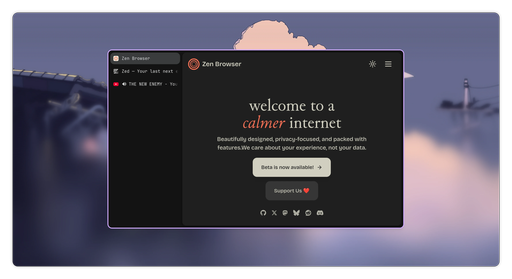

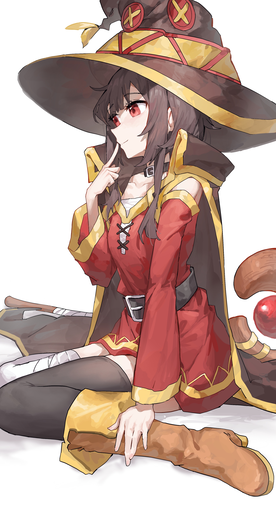

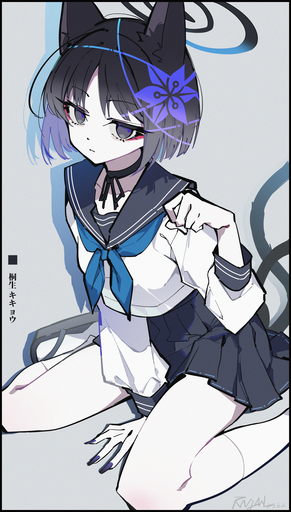

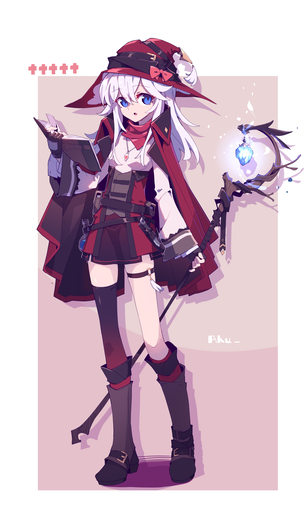

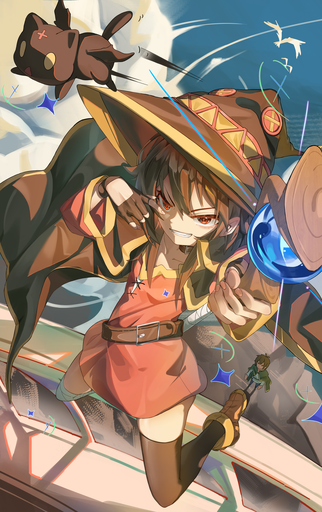

In [5]:
flt: ImageFilter = {"formats": ["PNG", "JPG"], "min_rating": 3}

show(filter_images(images, flt))

#### Big landscape images 🌄

83/101 images matched


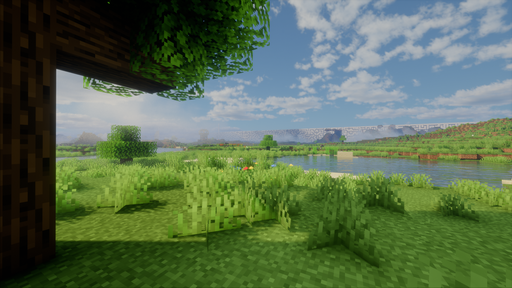

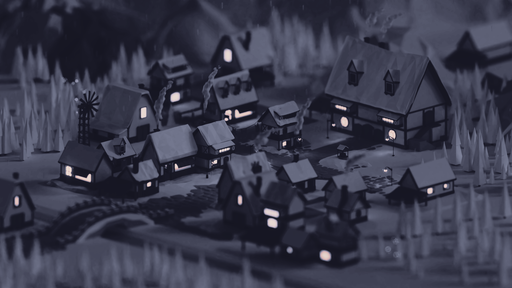

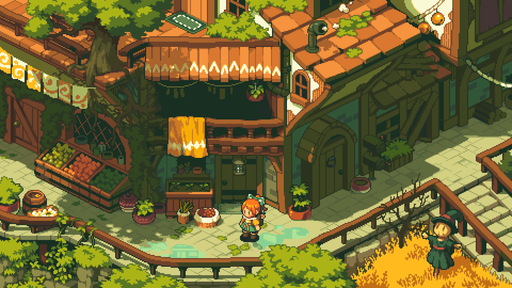

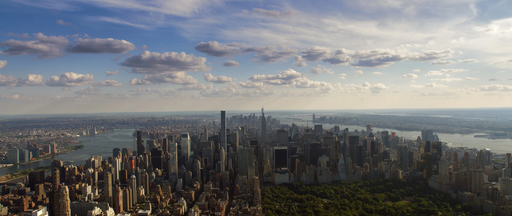

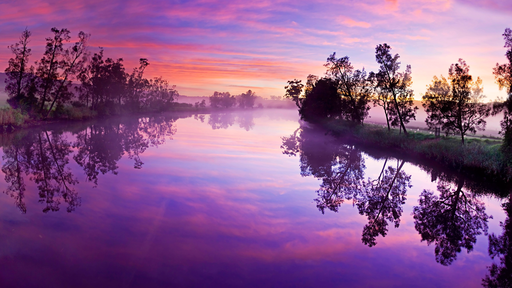

In [6]:
flt: ImageFilter = {"orientation": "landscape", "min_width": 1920, "min_height": 1080}

show(filter_images(images, flt))

#### Tags 🏷️

Tags written by the tagging notebooks (e.g. `02_tagging_yolo.ipynb`) can be used too.

8/101 images matched


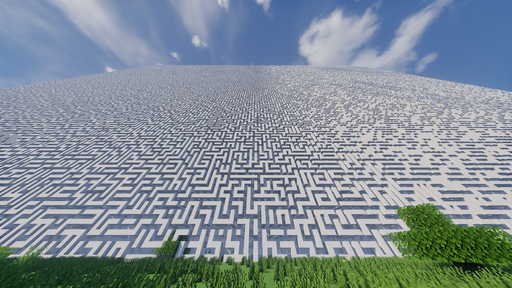

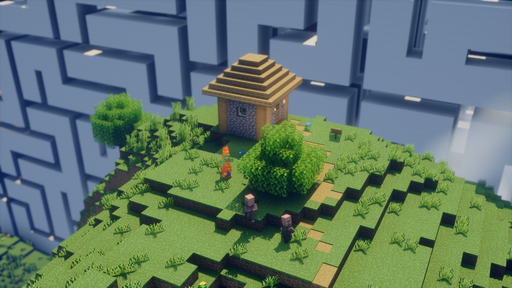

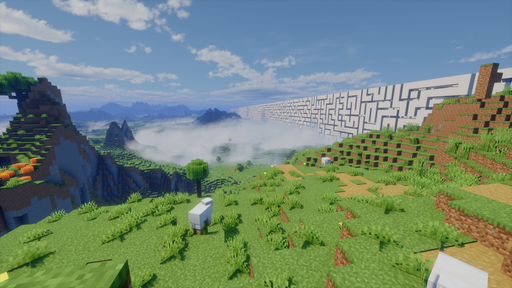

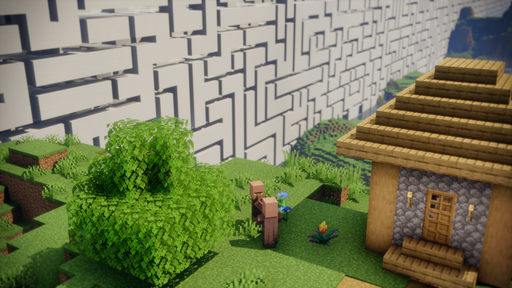

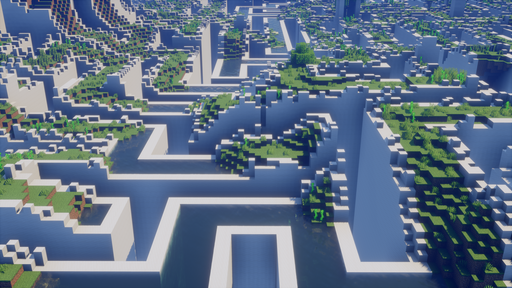

In [7]:
flt: ImageFilter = {"tags_any": ["maze", "city"]}

show(filter_images(images, flt))

26/101 images matched


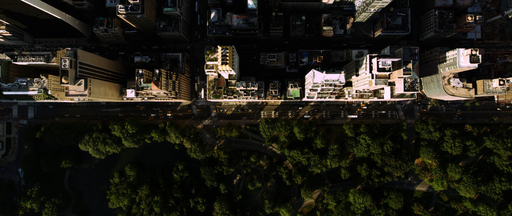

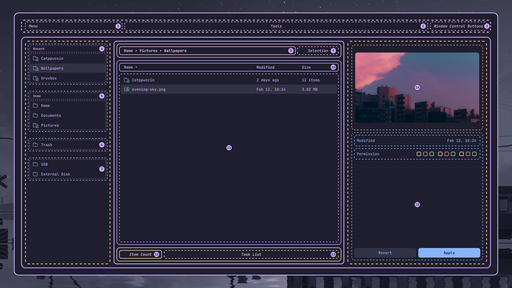

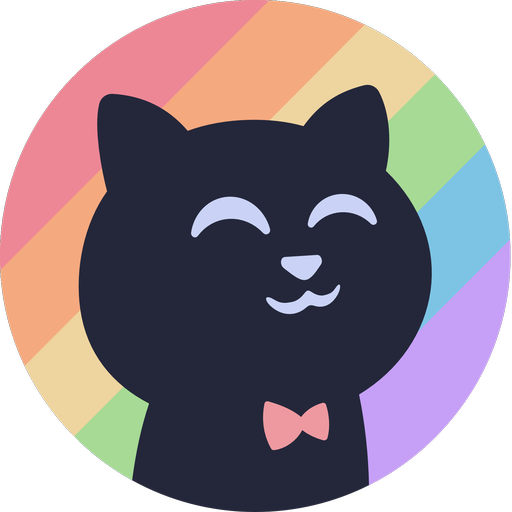

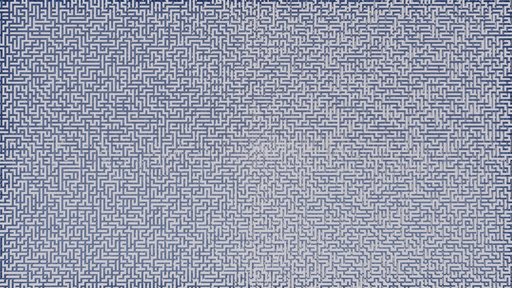

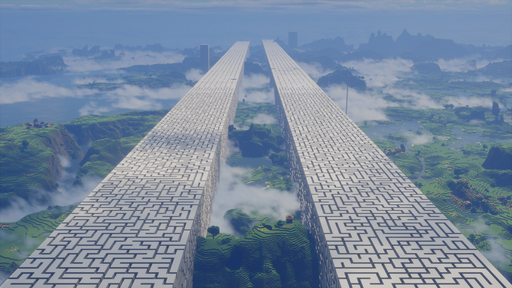

In [8]:
# Images nobody tagged yet
flt: ImageFilter = {"has_tags": False}

show(filter_images(images, flt))

#### Dominant color 🎨

14/101 images matched


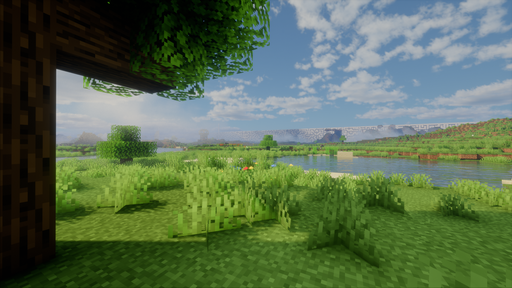

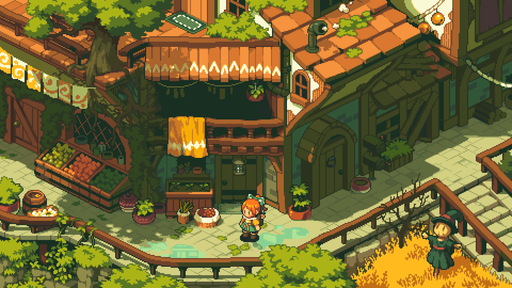

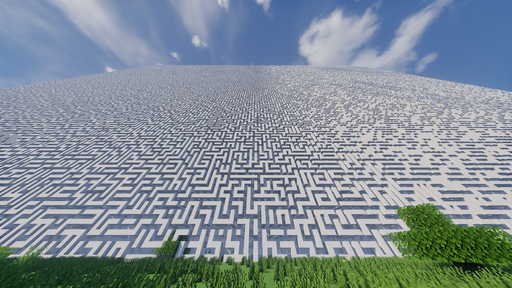

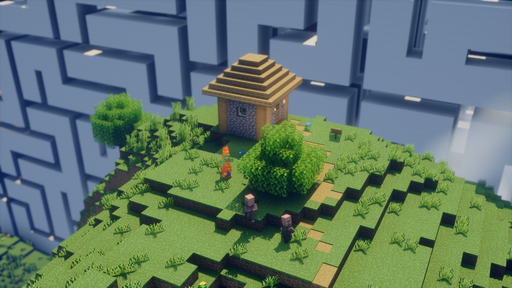

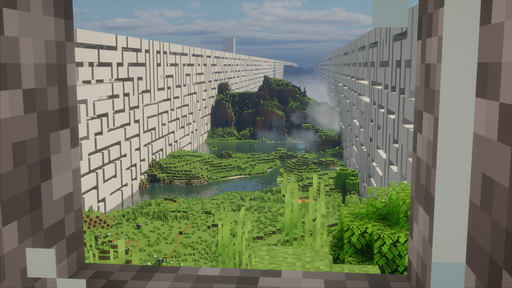

In [9]:
flt: ImageFilter = {"color": "#42692f", "color_distance": 40}

show(filter_images(images, flt))

#### Date 📅

1/101 images matched


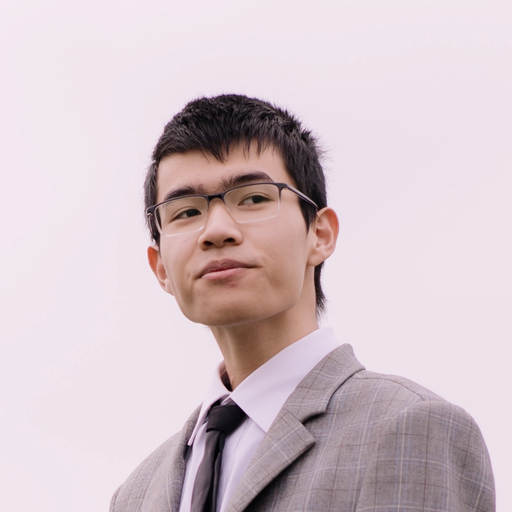

In [10]:
from datetime import datetime

flt: ImageFilter = {"modified_after": datetime(2025, 1, 1), "modified_before": datetime(2026, 1, 1)}

show(filter_images(images, flt))

#### Combine them all 🧩

In [11]:
flt: ImageFilter = {
    "formats": ["PNG"],
    "orientation": "portrait",
    "min_rating": 4,
    "tags_all": ["girl"],
    "color": "#c29880",
}

show(filter_images(images, flt))

0/101 images matched
